# 07 — Drift observado em `cs-test`: estimativa por razão de densidades

> **Versão SPW=13.882494684620836.** Esta suíte usa um novo retreino com `scale_pos_weight=13.882494684620836` e limiar fixo `0,50`. O desenho do `model_final.ipynb` foi mantido, exceto pelo peso de classe solicitado. O modelo congelado e sua configuração estão em `models/`; os dados de entrada devem estar em `data/raw/`.


Este caderno usa **a distribuição observada** em `cs-test.csv` para estimar o desempenho do modelo em uma população semelhante, sem inventar um cenário paramétrico. Como o arquivo não tem rótulos, o resultado continua sendo uma **estimativa condicionada** à hipótese de *covariate shift*: o risco de inadimplência dado o perfil $X$ deve continuar aproximadamente estável e a nova população precisa estar coberta pelos dados rotulados.

Treinamos um classificador de domínio apenas com $X$ para distinguir `cs-training` de `cs-test`. Com amostras balanceadas de ambas, a razão $r(x)=P(\mathrm{test}\mid x)/[1-P(\mathrm{test}\mid x)]$ aproxima $p_{test}(x)/p_{training}(x)$. Aplicamos essa razão ao **holdout rotulado** do split original, nunca usado no treinamento do modelo de crédito. Desempenho ponderado é calculado no holdout; nada aqui usa `SeriousDlqin2yrs` de `cs-test`.

Esta técnica foi estudada para *covariate shift* por [Sugiyama et al.](https://www.jmlr.org/papers/v8/sugiyama07a.html). O classificador de duas amostras é descrito por [Lopez-Paz e Oquab](https://arxiv.org/abs/1610.06545). Uma AUC de domínio próxima de 0,5 é compatível com distribuições difíceis de distinguir, mas não prova igualdade e pode tornar a estimativa da razão de densidades pouco informativa.


In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, roc_curve, auc, brier_score_loss
from IPython.display import display

SEED=33
P=DATA_DIR_PROJECT
DATA_DIR=next((d for d in (P,P.parent) if (d/'cs-training.csv').is_file()),None)
if DATA_DIR is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
OUT_DIR = TABLES_DIR
FEATURES=[
 'RevolvingUtilizationOfUnsecuredLines','age','NumberOfTime30-59DaysPastDueNotWorse',
 'DebtRatio','MonthlyIncome','NumberOfOpenCreditLinesAndLoans','NumberOfTimes90DaysLate',
 'NumberRealEstateLoansOrLines','NumberOfTime60-89DaysPastDueNotWorse','NumberOfDependents']
TARGET='SeriousDlqin2yrs'
sns.set_theme(style='whitegrid')
assert (MODEL_DIR / 'model_class_retreinado.json').exists()

In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Separar referência rotulada e alvo sem rótulos

Repete exatamente o split do notebook original. Os mínimos e máximos são observados apenas no treino usado pelo modelo.

In [4]:
df=pd.read_csv(DATA_DIR/'cs-training.csv').drop(columns=['Unnamed: 0'])
target_df=pd.read_csv(DATA_DIR/'cs-test.csv').drop(columns=['Unnamed: 0'])
assert df[TARGET].notna().all() and target_df[TARGET].isna().all()
X=df[FEATURES]; y=df[TARGET].astype(int)
X_tv,X_hold,y_tv,y_hold=train_test_split(X,y,test_size=.15,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_tv,y_tv,test_size=.1765,random_state=SEED)
X_target=target_df[FEATURES]
model=xgb.Booster(); model.load_model(str(MODEL_DIR / 'model_class_retreinado.json'))
model.set_param({'device':'cpu'})
assert model.num_boosted_rounds()==_manifesto_versao['num_boosted_rounds']
def predict(frame):
    dm=xgb.DMatrix(frame[FEATURES],feature_names=FEATURES,enable_categorical=True)
    return model.predict(dm,iteration_range=(0,model.num_boosted_rounds()))
p_hold=predict(X_hold); p_target=predict(X_target)
print(f'Holdout rotulado: {len(X_hold):,}; cs-test sem rótulos: {len(X_target):,}')
print(f'Scores médios: holdout {p_hold.mean():.4f}; cs-test {p_target.mean():.4f}')

Holdout rotulado: 22,500; cs-test sem rótulos: 101,503
Scores médios: holdout 0.3240; cs-test 0.3224


## 2. Classificador de domínio e cobertura de suporte

A amostragem balanceada define prior 1/2 para cada domínio, simplificando a razão de densidades. A avaliação da AUC de domínio ocorre em linhas separadas do ajuste. A tabela de suporte registra valores de `cs-test` além dos mínimos e máximos observados em `X_train`; qualquer extrapolação fica fora da garantia da reponderação.

In [5]:
rng=np.random.default_rng(SEED)
n_domain=min(50000,len(X_train),len(X_target))
source_sample=X_train.sample(n_domain,random_state=SEED)
target_sample=X_target.sample(n_domain,random_state=SEED)
Xd=pd.concat([source_sample,target_sample],ignore_index=True)
yd=np.r_[np.zeros(n_domain,dtype=int),np.ones(n_domain,dtype=int)]
Xd_fit,Xd_val,yd_fit,yd_val=train_test_split(Xd,yd,test_size=.30,random_state=SEED,stratify=yd)
domain=HistGradientBoostingClassifier(max_iter=75,max_leaf_nodes=15,learning_rate=.07,l2_regularization=2.0,random_state=SEED)
domain.fit(Xd_fit,yd_fit)
p_domain_val=domain.predict_proba(Xd_val)[:,1]
auc_domain=roc_auc_score(yd_val,p_domain_val)
boot_auc=[]
for _ in range(200):
    ix=rng.integers(0,len(yd_val),len(yd_val))
    boot_auc.append(roc_auc_score(yd_val[ix],p_domain_val[ix]))
print(f'AUC de domínio: {auc_domain:.4f}; IC bootstrap 95% [{np.quantile(boot_auc,.025):.4f}, {np.quantile(boot_auc,.975):.4f}]')
range_rows=[]
for f in FEATURES:
    low,high=X_train[f].min(),X_train[f].max()
    observed=X_target[f].notna()
    outside=((X_target[f]<low)|(X_target[f]>high)) & observed
    range_rows.append({'variavel':f,'min_treino':low,'max_treino':high,
                       'n_fora':int(outside.sum()),'fracao_fora':outside.mean(),
                       'fracao_ausente_test':1-observed.mean()})
range_table=pd.DataFrame(range_rows).sort_values('fracao_fora',ascending=False)
display(range_table)

AUC de domínio: 0.5004; IC bootstrap 95% [0.4938, 0.5066]


,variavel,min_treino,max_treino,n_fora,fracao_fora,fracao_ausente_test
4,MonthlyIncome,0.0,3008750.0,4,0.000039,0.198053
5,NumberOfOpenCreditLinesAndLoans,0.0,58.0,2,0.000020,0.000000
9,NumberOfDependents,0.0,13.0,2,0.000020,0.025871
0,RevolvingUtilizationOfUnsecuredLines,0.0,50708.0,0,0.000000,0.000000
1,age,0.0,109.0,0,0.000000,0.000000
3,DebtRatio,0.0,329664.0,0,0.000000,0.000000
2,NumberOfTime30-59DaysPastDueNotWorse,0.0,98.0,0,0.000000,0.000000
6,NumberOfTimes90DaysLate,0.0,98.0,0,0.000000,0.000000
7,NumberRealEstateLoansOrLines,0.0,54.0,0,0.000000,0.000000
8,NumberOfTime60-89DaysPastDueNotWorse,0.0,98.0,0,0.000000,0.000000


## 3. Estimar métricas ponderadas e sensibilidade ao limite de pesos

O classificador de domínio não viu o holdout do modelo de crédito. Sua razão estimada de densidades repondera as linhas rotuladas. Mostramos pesos sem corte e versões limitadas aos quantis 1–99% e 5–95%; a escolha altera o viés e a variância, portanto **nenhuma versão é adotada como verdade**. O ESS mede o suporte efetivo.

As quatro métricas centrais são Brier (menor é melhor), AUC ROC, **PR-AUC trapezoidal** e KS do modelo (as três últimas maiores são melhores). PR-AUC é a área trapezoidal de `precision_recall_curve`; AP, calculada separadamente, é uma soma em degraus e fica como informação adicional. Recall e precisão usam o corte 0,50 somente como referência descritiva. `cs-test` não tem rótulos: os valores abaixo são estimativas transportadas do holdout sob estabilidade de $P(Y\mid X)$, não desempenho observado naquele arquivo.

In [6]:
def metrics(y_true,p,w):
    yy=np.asarray(y_true,dtype=int); pp=np.asarray(p,dtype=float); ww=np.asarray(w,dtype=float)
    assert len(yy)==len(pp)==len(ww) and np.all(ww>=0) and ww.sum()>0
    fpr,tpr,_=roc_curve(yy,pp,sample_weight=ww)
    precision_curve,recall_curve,_=precision_recall_curve(yy,pp,sample_weight=ww)
    pred=pp>=.5
    tp=ww[(yy==1)&pred].sum(); fn=ww[(yy==1)&~pred].sum()
    fp=ww[(yy==0)&pred].sum(); tn=ww[(yy==0)&~pred].sum()
    prev=np.average(yy,weights=ww)
    # AP é a soma em degraus da curva PR; não confundir com a área trapezoidal.
    ap=float(-np.sum(np.diff(recall_curve)*precision_curve[:-1]))
    return {'auc':float(auc(fpr,tpr)),'prauc_trap':float(auc(recall_curve,precision_curve)),
            'ks_modelo':float(np.max(tpr-fpr)),'ap':ap,'ap_lift':ap/prev,
            'brier':brier_score_loss(yy,pp,sample_weight=ww),
            'recall':tp/(tp+fn),'precision':tp/(tp+fp) if tp+fp else np.nan,
            'fpr':fp/(fp+tn),'prevalencia':prev,
            'ess':ww.sum()**2/np.square(ww).sum(),
            'ess_fracao':ww.sum()**2/np.square(ww).sum()/len(ww)}

domain_p=np.clip(domain.predict_proba(X_hold)[:,1],.02,.98)
ratio=domain_p/(1-domain_p) # priors balanceados (1/2, 1/2)
weighted={}
for name,q in [('sem_corte',None),('quantis_1_99',(.01,.99)),('quantis_5_95',(.05,.95))]:
    if q is None: w=ratio.copy()
    else: w=np.clip(ratio,*np.quantile(ratio,q))
    weighted[name]=w/w.mean()
baseline=metrics(y_hold,p_hold,np.ones(len(y_hold)))
rows=[{'metodo':'sem_ponderacao',**baseline}]
rows += [{'metodo':name,**metrics(y_hold,p_hold,w)} for name,w in weighted.items()]
results=pd.DataFrame(rows)
for col in ['auc','prauc_trap','ks_modelo','brier','ap','recall','precision']:
    results['delta_'+col]=results[col]-baseline[col]
display(results.round(5))
print('Razão de densidades bruta, quantis 1/50/99%:',np.quantile(ratio,[.01,.5,.99]).round(4))
results.to_csv(OUT_DIR/'resultados_drift_observado.csv',index=False,encoding='utf-8-sig')

,metodo,auc,prauc_trap,ks_modelo,ap,ap_lift,brier,recall,precision,fpr,prevalencia,ess,ess_fracao,delta_auc,delta_prauc_trap,delta_ks_modelo,delta_brier,delta_ap,delta_recall,delta_precision
0,sem_ponderacao,0.86684,0.39599,0.58771,0.39639,5.94578,0.14404,0.79400,0.21525,0.20676,0.06667,22500.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,sem_corte,0.86741,0.39818,0.58874,0.39858,5.93319,0.14463,0.79633,0.21605,0.20809,0.06718,22481.20451,0.99916,0.00057,0.00218,0.00102,0.00059,0.00219,0.00233,0.00079
2,quantis_1_99,0.86738,0.39797,0.58869,0.39837,5.93108,0.14463,0.79627,0.21601,0.20808,0.06717,22484.68943,0.99932,0.00054,0.00198,0.00097,0.00059,0.00198,0.00227,0.00076
3,quantis_5_95,0.86733,0.39770,0.58862,0.39810,5.93050,0.14460,0.79614,0.21593,0.20802,0.06713,22489.24467,0.99952,0.00049,0.00171,0.00091,0.00056,0.00172,0.00214,0.00068


Razão de densidades bruta, quantis 1/50/99%: [0.9129 0.9981 1.0955]


## 4. Incerteza da comparação com a linha de base

Reamostramos as **mesmas** linhas do holdout e calculamos o delta entre versão ponderada e basal em cada réplica. O intervalo percentil de 95% é descritivo e condicional ao modelo e ao classificador de domínio já ajustados; não incorpora incerteza da razão de densidades nem possível alteração de $P(Y\mid X)$. Um intervalo que inclua zero não prova equivalência.

In [7]:
rng=np.random.default_rng(SEED+77)
boot=[]
w=weighted['quantis_1_99']
y_arr=np.asarray(y_hold)
metricas_centrais=['auc','prauc_trap','ks_modelo','brier']
for _ in range(100):
    idx=rng.integers(0,len(y_arr),len(y_arr))
    b0=metrics(y_arr[idx],p_hold[idx],np.ones(len(idx)))
    b1=metrics(y_arr[idx],p_hold[idx],w[idx])
    boot.append({k:b1[k]-b0[k] for k in metricas_centrais})
boot_df=pd.DataFrame(boot)
ci=pd.DataFrame({'delta_observado':{k:results.loc[results.metodo=='quantis_1_99','delta_'+k].iloc[0] for k in boot_df},
                 'ic95_inferior':boot_df.quantile(.025),'ic95_superior':boot_df.quantile(.975)})
display(ci.round(5))

,delta_observado,ic95_inferior,ic95_superior
auc,0.00054,0.00028,0.00077
prauc_trap,0.00198,0.00081,0.00312
ks_modelo,0.00097,0.00022,0.00154
brier,0.00059,0.00051,0.00069


## 5. Visualizar a diferença observada

Os três primeiros painéis auditam se as populações são distinguíveis, se os pesos concentram a estimativa e como os scores mudam sem rótulos. O quarto cruza AUC e Brier ponderados. O gráfico complementar exibe **deltas das quatro métricas centrais**, sempre cenário menos holdout basal. Em Brier, delta positivo é pior; nas outras três, delta negativo é pior. A mudança pode decorrer apenas da composição e prevalência. Nada aqui mede desempenho verdadeiro no arquivo sem rótulos.

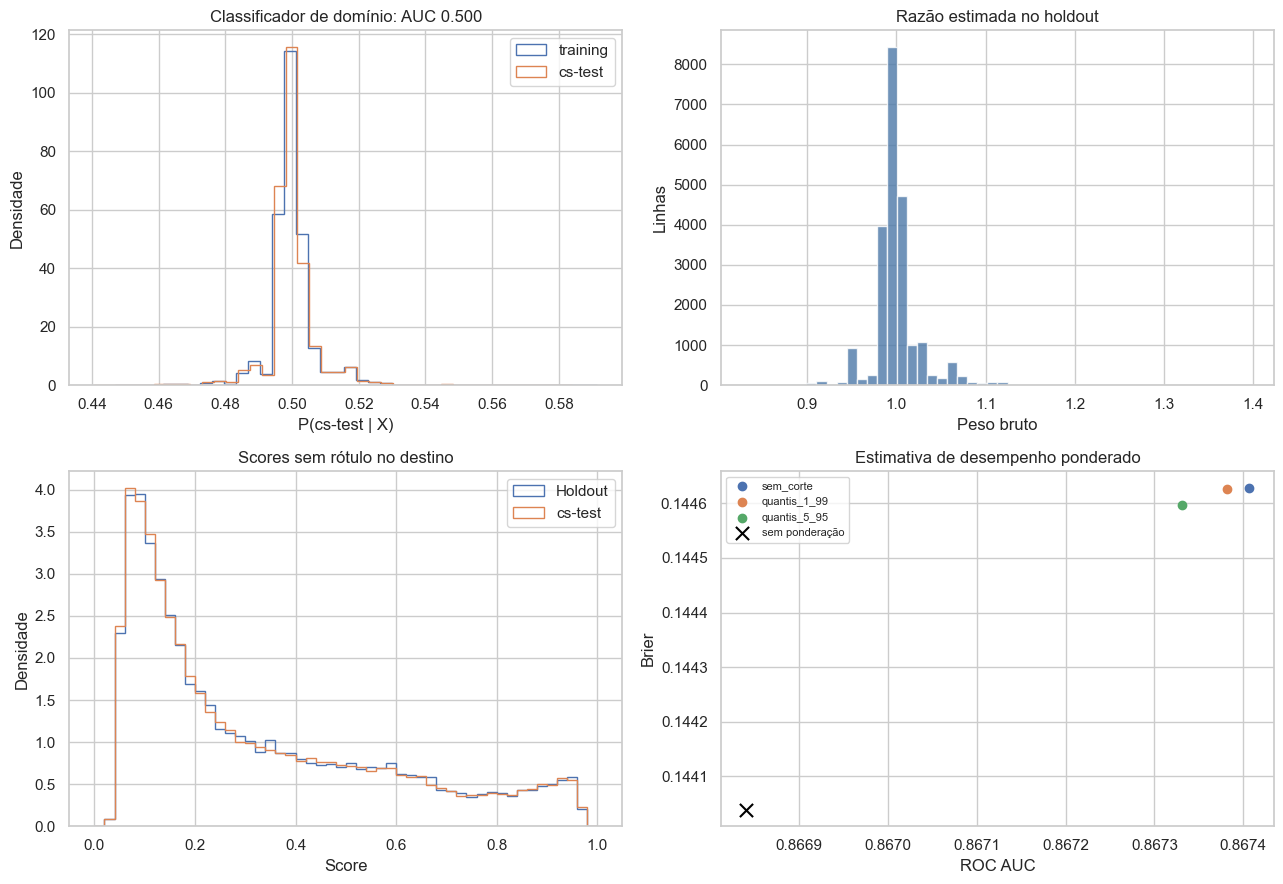

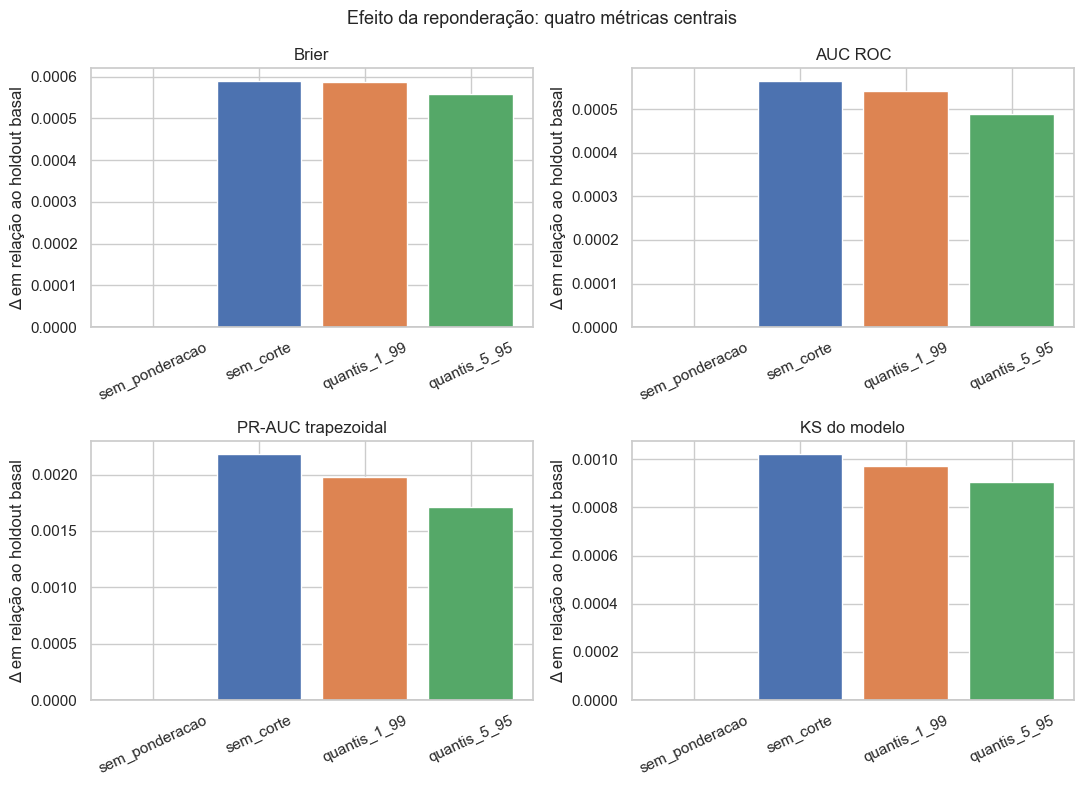

In [8]:
fig,ax=plt.subplots(2,2,figsize=(13,9))
ax[0,0].hist(p_domain_val[yd_val==0],bins=40,density=True,histtype='step',lw=2,label='training')
ax[0,0].hist(p_domain_val[yd_val==1],bins=40,density=True,histtype='step',lw=2,label='cs-test')
ax[0,0].set(title=f'Classificador de domínio: AUC {auc_domain:.3f}',xlabel='P(cs-test | X)',ylabel='Densidade');ax[0,0].legend()
ax[0,1].hist(ratio,bins=50,color='#4c78a8',alpha=.8)
ax[0,1].set(title='Razão estimada no holdout',xlabel='Peso bruto',ylabel='Linhas')
bins=np.linspace(0,1,51)
ax[1,0].hist(p_hold,bins=bins,density=True,histtype='step',lw=2,label='Holdout')
ax[1,0].hist(p_target,bins=bins,density=True,histtype='step',lw=2,label='cs-test')
ax[1,0].set(title='Scores sem rótulo no destino',xlabel='Score',ylabel='Densidade');ax[1,0].legend()
for name,w in weighted.items():
    ax[1,1].scatter(metrics(y_hold,p_hold,w)['auc'],metrics(y_hold,p_hold,w)['brier'],label=name)
ax[1,1].scatter(baseline['auc'],baseline['brier'],color='black',marker='x',s=90,label='sem ponderação')
ax[1,1].set(title='Estimativa de desempenho ponderado',xlabel='ROC AUC',ylabel='Brier');ax[1,1].legend(fontsize=8)
plt.tight_layout();plt.show()

fig,axs=plt.subplots(2,2,figsize=(11,8))
for axis,k,titulo in zip(axs.flat,['brier','auc','prauc_trap','ks_modelo'],
                          ['Brier','AUC ROC','PR-AUC trapezoidal','KS do modelo']):
    axis.bar(results.metodo,results['delta_'+k],color=['gray','C0','C1','C2'])
    axis.axhline(0,color='black',lw=1)
    axis.tick_params(axis='x',rotation=25)
    axis.set(title=titulo,ylabel='Δ em relação ao holdout basal')
fig.suptitle('Efeito da reponderação: quatro métricas centrais',fontsize=13)
fig.tight_layout();plt.show()

## Interpretação

- O classificador de domínio mede se `cs-test` difere do histórico nas entradas. O método de reponderação só estima desempenho se $P(Y\mid X)$ permanecer estável e se houver sobreposição de suporte.
- Observações além do intervalo de treino estão na tabela de cobertura. A reponderação de linhas históricas **não testa** o comportamento do modelo além dos limites; o notebook 06 faz ensaios de score/decisão nessas regiões.
- O classificador e as métricas condicionadas devem ser revalidados quando aparecerem rótulos reais de uma safra futura. Decisões de crédito podem criar viés de observação do desfecho, dependendo de quem recebe aprovação.
